# SQuADDS Tutorial 5 — a fab-ready 4-qubit chip (USC4Q_qff2024) (Quantcore PDK rebuild)

**What the chip is.** LFL-Lab **SQuADDS**, `tutorials/Tutorial-5_Designing_a_fab_ready_chip_with_SQuADDS.ipynb`
and its GDS `tutorials/gds_files/USC4Q_qff2024.gds`, <https://github.com/LFL-Lab/SQuADDS> — **MIT licence**
("Copyright (c) 2023 Sadman Ahmed Shanto"; notebook footer © Shanto & Levenson-Falk 2024). Depth-1 clone read
2026-11-03 (never executed). Spec: `docs/designs/squadds/tutorial_5_fab_ready_chip.md` (geometry the notebook does
not print was measured from the GDS). Built with Quantum Metal plus SQuADDS' `TransmonCross`.

Four identical grounded cross transmons (one SQuADDS database design: f_q ≈ 3.66 GHz, α ≈ −205 MHz, g ≈ 99 MHz)
on a 5 × 5 mm chip. Each has a λ/4 meander coupled to a straight vertical feedline through a `CoupledLineTee`, and
a charge line ending 50 µm past the cross pocket. The four resonators are "sprayed" over 5.48–8.48 GHz so that one
of them lands on ω₀₂ despite junction spread. Two feedline pads + four charge pads.

This notebook **rebuilds** that chip with our components, routes, netlist and LOM on the Quantcore PDK — not a
replica. We distribute the rebuild under GPL-3.0.

| topic | SQuADDS source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 5 × 5 mm chip | the 7.5 × 7.5 mm Quantcore die (`box=(-1250, -1250, 6250, 6250)`: the source's chip area centred in it, so every source coordinate is kept + (2500, 2500) µm), Quantcore die frame, device ID "USC4Q" |
| pads | 2 feedline + 4 charge-line `LaunchpadWirebond`s on the 5 mm chip | the same six launchpads moved to **100 µm** from the die edge (`frame.pad_edge`, `edge="auto"`); the feedline and the charge lines get longer |
| substrate | silicon (the SQuADDS database) | sapphire 650 µm, εr 10.25: the frequencies differ from the source's |
| junctions | Dolan, L_J 15.904 nH (database), f_q target 3.7 GHz | Quantcore trilayer junction **sized for 4.05 GHz** (the PDK band's floor): 0.25 × 0.6 µm, L_J ≈ 13.5 nH, **R_n ≈ 92 kΩ, above the 40–50 kΩ window** (flagged, not retuned) |
| cheese | Metal's GDS-renderer cheese: 25 µm holes on a 125 µm pitch, 100 µm clear of the metal, 200 µm from the chip edge | **the original wins:** the same rule as the chip's `cheese` dict (`metal_cheese_rule(buffer=100, size=25, pitch=125, edge=200)`), drawn by the build instead of the PDK band |
| elements, positions, routes | — | kept: the Metal components with the source's options and positions, the readout lengths, the hanger couplers at the source's centres (`near=`), the charge-line paths |
| placement | centred | centred (checked below) |

**Reproduced (Metal components through the `metal:` wrapper):** `TransmonCross` qubits (cross 210 / 30 / 30 µm, one
claw toward the line, connector at 90°, no claw CPW) at the source positions and orientations; `LaunchpadWirebond`
feedline pads (160 × 80 µm pad, 122 µm taper, 25 µm lead, read from the GDS; feedline 11.7/5.1 µm) and charge-line
pads (150 × 200 µm, 122 µm taper); the readout lengths **including** the tee's coupled part (GDS: 4570 / 3930 / 3460
/ 3100 µm for Q1–Q4); the 325 µm coupled sections with a 7.9 µm ground strip (coupled trace 29.8 µm from the
feedline centre; resonator gap 5.1 µm assumed), shorted; the charge lines with their open ends 284 µm from the qubit
centre (50 µm past the pocket), one corner each (r = 40 µm; the source fillet of 80 µm does not fit the 116 µm leg
of Q2's line in our router).

**Assumed / substituted:** the database row's claw options are not printed in the notebook: claw 190 µm long,
15 µm wide (GDS), `claw_gap` 5.1 µm and `ground_spacing` 9 µm (assumed, so that the claw sits ≈ 39 µm from the cross
as measured in the GDS). Metal's `TransmonCross` stands in for the SQuADDS subclass (same geometry; its Dolan
junction is the Quantcore trilayer junction here). Each `CoupledLineTee` + `RouteMeander` is one qcc λ/4 hanger
route; the meander is KQC's (8 turns, r = 30.9 µm, the source fillet).

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its own
cell with a picture of the chip so far — the die with the source's cheese rule, the six launchpads, the feedline, the four cross
transmons with their junction sized on the PDK rule, their λ/4 hanger readouts, the four charge lines, and then the
whole chip (the targets and sim groups, the centring, the save). Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in a few cells, with its outputs) is kept as `tutorial_5_fab_ready_chip.v1.ipynb`; both save the same
`tutorial_5_fab_ready_chip.json`.

## Setup

`LIVE` follows `QCC_LIVE` (default on: KLayout opens and redraws after every change; `QCC_LIVE=0` for batch
runs). `FULL_FAB = False` skips the fab-only corner rounding in the fab step (`qcc mask` writes the full file). The segment pictures go to `build/snapshots/tutorial_5_fab_ready_chip/` (`STEPS`, not
kept in the repo), the final snapshots and the design JSON next to the notebook (`OUT`).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.circuit.bridges import size_junction

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
FULL_FAB = False                                 # True: also round the corners in the fab export (slow here)
OUT = Path("examples/designs/squadds")                        # design JSON + final snapshots
STEPS = Path("build/snapshots/tutorial_5_fab_ready_chip")  # step-by-step snapshots (build/ is not kept in the repo)

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The chip is built the way a designer would lay it out by hand: the die, the bond pads, the readout, the qubits, the
coupling, the control lines, and then the whole chip. Each segment is one cell with one picture of the chip so far
(and, live, KLayout redraws after every cell). A route joins two ports, or a port and a hanger on another route, so the feedline is drawn as soon as its
pads exist (segment 3), each readout once its qubit is there (segment 5) and each charge line after it (segment 7).
Every position is a source coordinate + (2500, 2500) µm, so the order changes nothing.

| segment | what is placed here |
|---|---|
| 1 | the 7.5 × 7.5 mm Quantcore die with the source's chip area centred in it, and the source's cheese rule |
| 2 | six launchpads: the feedline's two (north / south) and the four charge-line pads, on the PDK pad rule |
| 3 | the readout line: the straight 11.7/5.1 µm feedline |
| 4 | the junction sized for 4.05 GHz and the four `TransmonCross` qubits |
| 5 | the four λ/4 hanger readouts, "sprayed" over 5.48–8.48 GHz |
| 6 | the coupling: none (the four qubits are not coupled to each other) |
| 7 | the control routing: the four charge lines, ending open 284 µm from each qubit centre |
| 8 | the whole chip: the targets and sim groups, the centring, the save |

## Design 1 · The die and its frame

`Designer(...)` starts the chip on the 7.5 × 7.5 mm Quantcore die, with the source's 5 × 5 mm chip area centred in
it: a source point (x, y) (Metal's chip is centred on (0, 0)) sits at (x + `X0`, y + `Y0`) = (x + 2500, y + 2500) µm.
The chip name "USC4Q" is the device ID. The chip `cheese` is the source's own rule: Metal's GDS renderer cheesed
this chip with 25 µm squares on a 125 µm pitch, 100 µm clear of every metal shape and 200 µm from the edge;
`metal_cheese_rule` writes that as a chip `cheese` dict, which the build draws (layout, snapshots, KLive) instead of
the PDK band and `export_fab` / `qcc mask` keep. Its clearance is measured from the 3/0 keep-out, which already
adds the PDK margins, so the holes sit a few µm further from the metal than in the source.

cheese rule: {'size': 25.0, 'gap': 100.0, 'rows': 1000, 'clearance': 100.0, 'edge': 200.0}


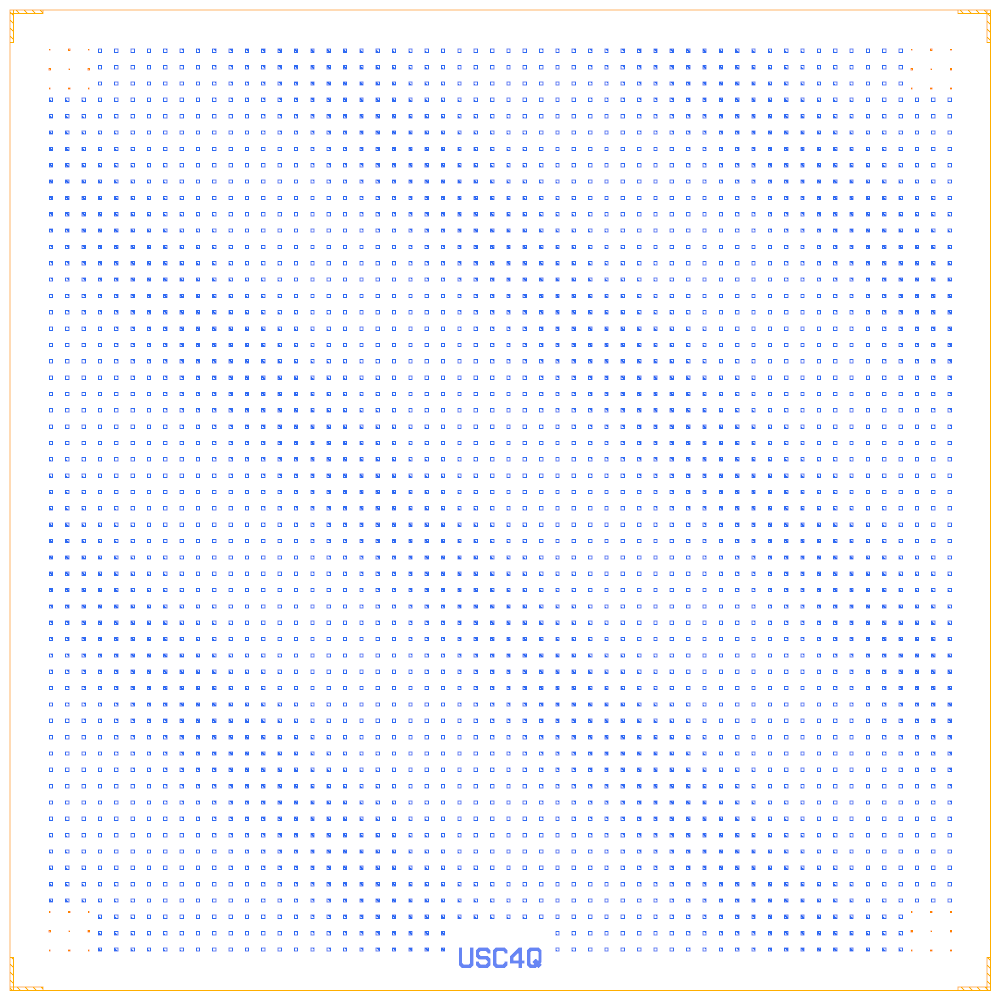

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('build/snapshots/tutorial_5_fab_ready_chip/1_die.png')

In [5]:
X0, Y0 = 2500, 2500                              # Metal's 5 × 5 mm chip is centred on (0, 0)
CHEESE = metal_cheese_rule(buffer=100, size=25, pitch=125, edge=200)   # the source's renderer cheese
print("cheese rule:", CHEESE)
d = Designer("tutorial_5_fab_ready_chip", box=(-1250, -1250, 6250, 6250),
             chip={"name_chip": "USC4Q", "cheese": CHEESE}, live=LIVE)
layout_step(d, STEPS / "1_die.png", size=(1000, 1000), width=400)

## Design 2 · Bond pads and the pad rule

Six Metal `LaunchpadWirebond`s at the source's positions: the feedline pads P_TOP and P_BOT, and the charge-line
pads LP1–LP4 at (±2000, ±1300) µm. **PDK rule:** the outer etch edge of a pad sits `frame.pad_edge` (100 µm) from
the die edge. `edge="auto"` in `d.add` applies it: each pad keeps its position along its nearest die edge and slides
perpendicular to it until its etch ends 100 µm from that edge. The table measures the result.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| P_TOP | `metal:LaunchpadWirebond` | n | 100.0 | ✓ |
| P_BOT | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |
| LP1 | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |
| LP2 | `metal:LaunchpadWirebond` | e | 100.0 | ✓ |
| LP3 | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |
| LP4 | `metal:LaunchpadWirebond` | e | 100.0 | ✓ |

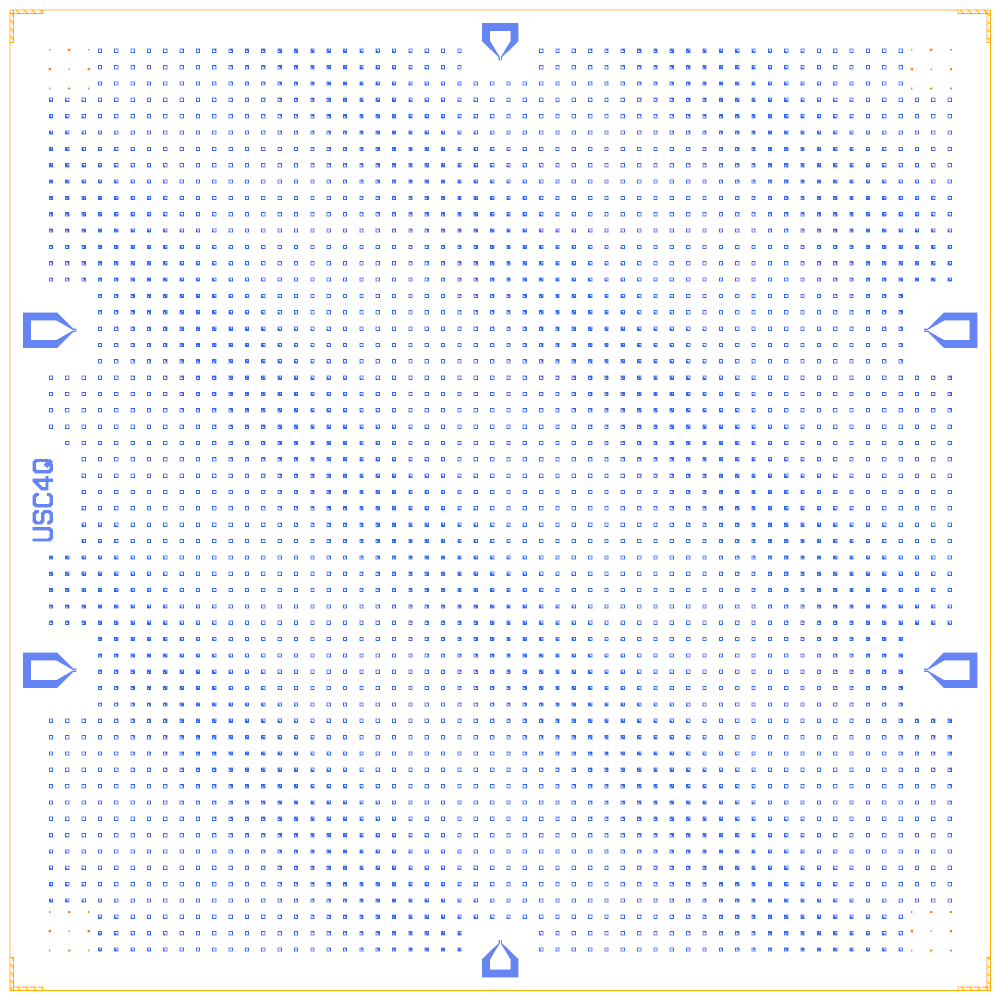

**On the chip so far:** 6 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 6 component(s) `P_TOP`, `P_BOT`, `LP1`, `LP2`, `LP3`, `LP4`.

WindowsPath('build/snapshots/tutorial_5_fab_ready_chip/2_pads.png')

In [6]:
FEED_PAD = dict(trace_width=11.7, trace_gap=5.1, lead_length=25, pad_width=160, pad_height=80, taper_height=122)   # GDS
CL_PAD = dict(trace_width=10, trace_gap=6, lead_length=25, pad_width=150, pad_height=200, taper_height=122)      # GDS
with d.batch():
    top = d.add("P_TOP", "metal:LaunchpadWirebond", at=(X0, Y0 + 2100), rot=-90, edge="auto", **FEED_PAD)
    bot = d.add("P_BOT", "metal:LaunchpadWirebond", at=(X0, Y0 - 1900), rot=90, edge="auto", **FEED_PAD)
    for i, (x, y) in enumerate(((-2000, 1300), (2000, 1300), (-2000, -1300), (2000, -1300)), start=1):
        d.add(f"LP{i}", "metal:LaunchpadWirebond", at=(X0 + x, Y0 + y), rot=0 if x < 0 else 180, edge="auto",
              **CL_PAD)
rebuild(d)                                       # a live=False Designer builds on request: the table reads this build
display(Markdown(pads_md(d)))
layout_step(d, STEPS / "2_pads.png", size=(1000, 1000), width=400)

**From the v1 run:** all six pads end 100.0 µm from their die edge: P_TOP moved 1290 µm up, P_BOT 1490 µm down and the four charge pads 1270 µm out (west / east). The feedline is 2780 µm longer (6730 µm) and each charge line 1270 µm longer.

## Design 3 · Readout: the feedline

**The feedline** `FL` runs straight down from P_TOP's tie to P_BOT's (11.7/5.1 µm). It needs no qubit, so it comes first; the four readouts will hang on it (Design 5).

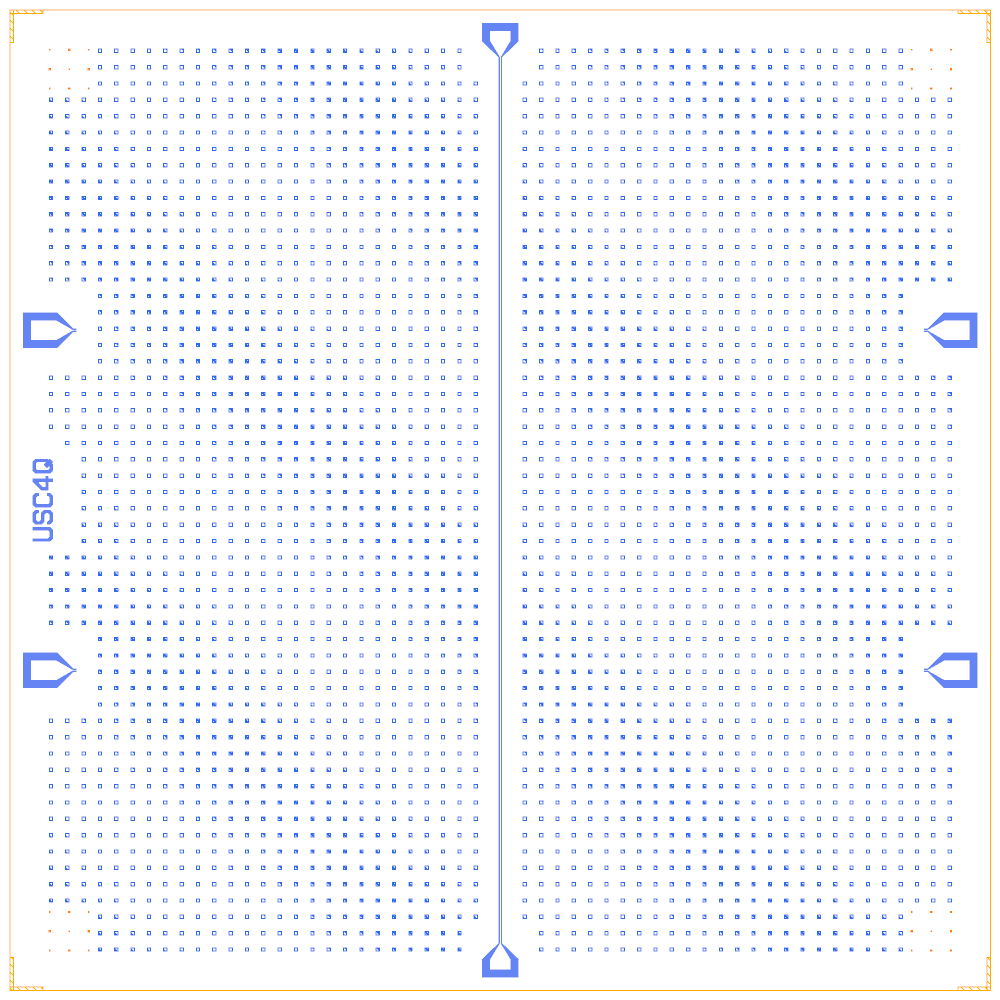

**On the chip so far:** 6 pads · 0 qubits · 0 other components · 1 routes · 0 declared couplings. **This step added** 1 route(s) `FL`.

WindowsPath('build/snapshots/tutorial_5_fab_ready_chip/s3_feedline.png')

In [7]:
with d.batch():
    fl = d.route("FL", top.tie, bot.tie, a=11.7, b=5.1)
layout_step(d, STEPS / "s3_feedline.png", size=(1000, 1000), width=400)

## Design 4 · Qubit placement: the junction and four cross transmons

**The junction from the PDK rule.** The source's target f_q (3.7 GHz) is below the PDK band (4–8 GHz), so each
junction is sized for 4.05 GHz, the band's floor, with the qubit's C_Σ from this design's LOM before the rebuild
(95.4 fF without the junction; the database's 15.904 nH + 2 fF gave 3.844 GHz). `size_junction` returns the
trilayer fingers and R_n; `trilayer_junction` gives the cell parameters (`JJ_PARAMS`) and the LOM / FEM junction
values (`JJ`). A 45 kΩ junction would put the qubits at ≈ 5.7 GHz, inside the 5.5–8.5 GHz readout spray, so the
rebuild keeps the 4.05 GHz sizing and the DRC flags its R_n. The targets stay the source's (3.7 GHz).

In [8]:
SIZED = size_junction(4.05, 95.4, c_includes_junction=False)
JJ_PARAMS, JJ = trilayer_junction("metal:TransmonCross", lj_nH=SIZED.lj_nH)
print(JJ, f"R_n {SIZED.rn_kohm:.0f} kΩ, fingers {SIZED.finger_width} × {SIZED.second_finger_width} µm;", *SIZED.notes)

{'Lj_nH': 13.4688, 'Cj_fF': 7.5} R_n 92 kΩ, fingers 0.25 × 0.6 µm; R_n 91.7 kΩ is outside the process window 40–50 kΩ (f_q 4.05 GHz with C_Σ 102.8 fF needs E_J/h 11.9 GHz)


Four Metal `TransmonCross` qubits through the `metal:` wrapper (bare numbers on length options are µm): a 210 µm
cross with 30 µm arms in a 30 µm gap, one claw (`connection_pads` "c") facing the feedline — 190 × 15 µm, 5.1 µm
gap, 9 µm ground spacing, at 90° — and the trilayer junction above. The west qubits (Q1, Q3) are rotated −90°,
the east ones (Q2, Q4) +90°, as in the source. Port `c` is the claw's connector; `squid_a` / `squid_b` are the
junction's attachment points (the qubit draws its own junction).

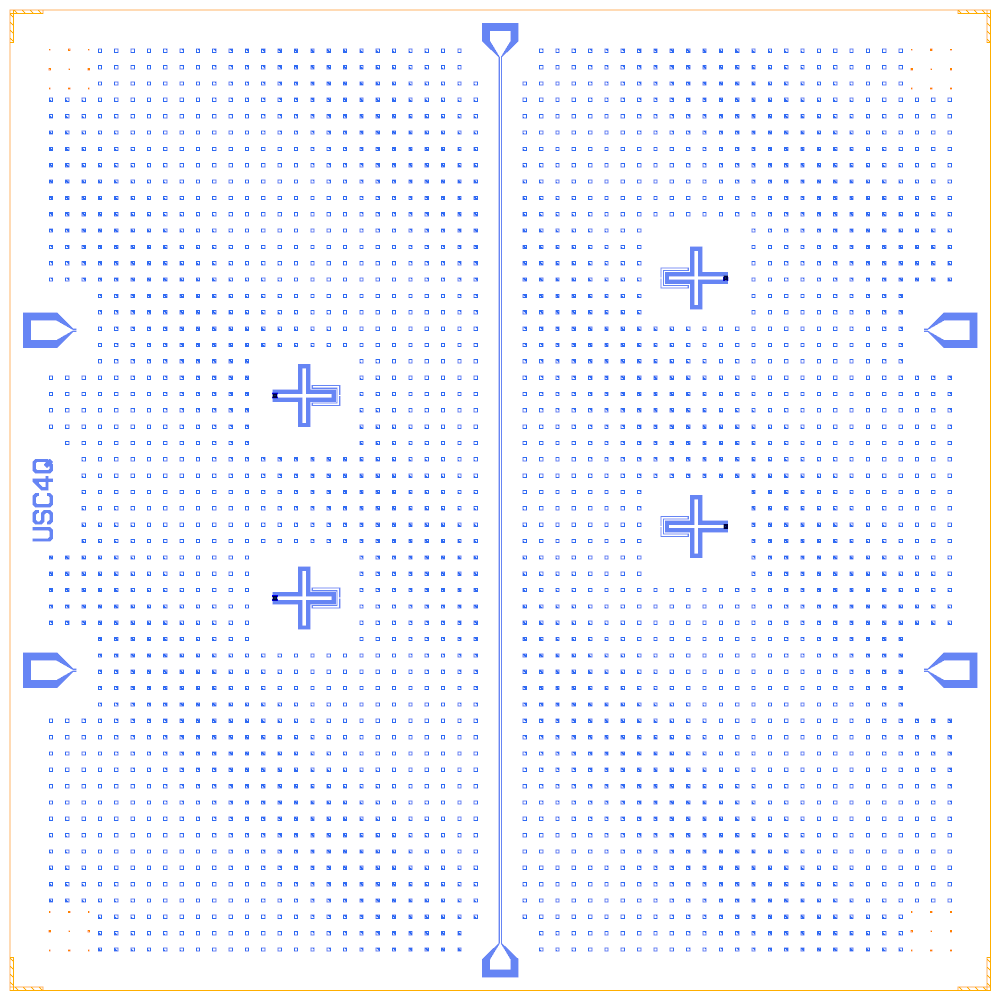

**On the chip so far:** 6 pads · 4 qubits · 0 other components · 1 routes · 0 declared couplings. **This step added** 4 component(s) `Q1`, `Q2`, `Q3`, `Q4`.

WindowsPath('build/snapshots/tutorial_5_fab_ready_chip/3_components.png')

In [9]:
CLAW = dict(connector_location="90", connector_type="0", claw_length=190, claw_width=15, claw_gap=5.1,
            ground_spacing=9, claw_cpw_length=0)                     # claw_gap / ground_spacing assumed
CROSS = dict(cross_length=210, cross_width=30, cross_gap=30, connection_pads={"c": CLAW})
# name, source (x, y), coupler centre s from P_TOP's source tie, direction, readout length (GDS, incl. tee), f target
QUBITS = (("Q1", (-1500, 800), 1262.5, "backward", 4570, 5.48), ("Q2", (1500, 1700), 387.5, "forward", 3930, 6.48),
          ("Q3", (-1500, -750), 2812.5, "backward", 3460, 7.48), ("Q4", (1500, -200), 2287.5, "forward", 3100, 8.48))
with d.batch():
    for name, (x, y), *_ in QUBITS:
        d.add(name, "metal:TransmonCross", at=(X0 + x, Y0 + y), rot=-90 if x < 0 else 90, junction=JJ, **JJ_PARAMS,
              **CROSS)
layout_step(d, STEPS / "3_components.png", size=(1000, 1000), width=400)

## Design 5 · Readout: four λ/4 hangers

**The readouts** are λ/4 hanger
routes from each claw: an 8-turn meander (r = 30.9 µm) and a 325 µm coupled section with a 7.9 µm ground strip,
shorted at its far end. The source places each coupler by its arclength `s` from P_TOP's tie; the pad rule moves
P_TOP 1290 µm up, which would slide every coupler, so the rebuild anchors each one by position instead:
`fl.hanger(near=(X0, Y_TIE − s), ...)` centres it at the feedline point nearest the source's coupler centre (Y_TIE
= 4575 µm, P_TOP's tie at the source position). `direction` sets which end is shorted. The router draws the length each path leaves over as one KQC `Meander` with the 8 turns asked for (fewer,
with a warning, only if 8 would be narrower than the 30.9 µm bend radius).

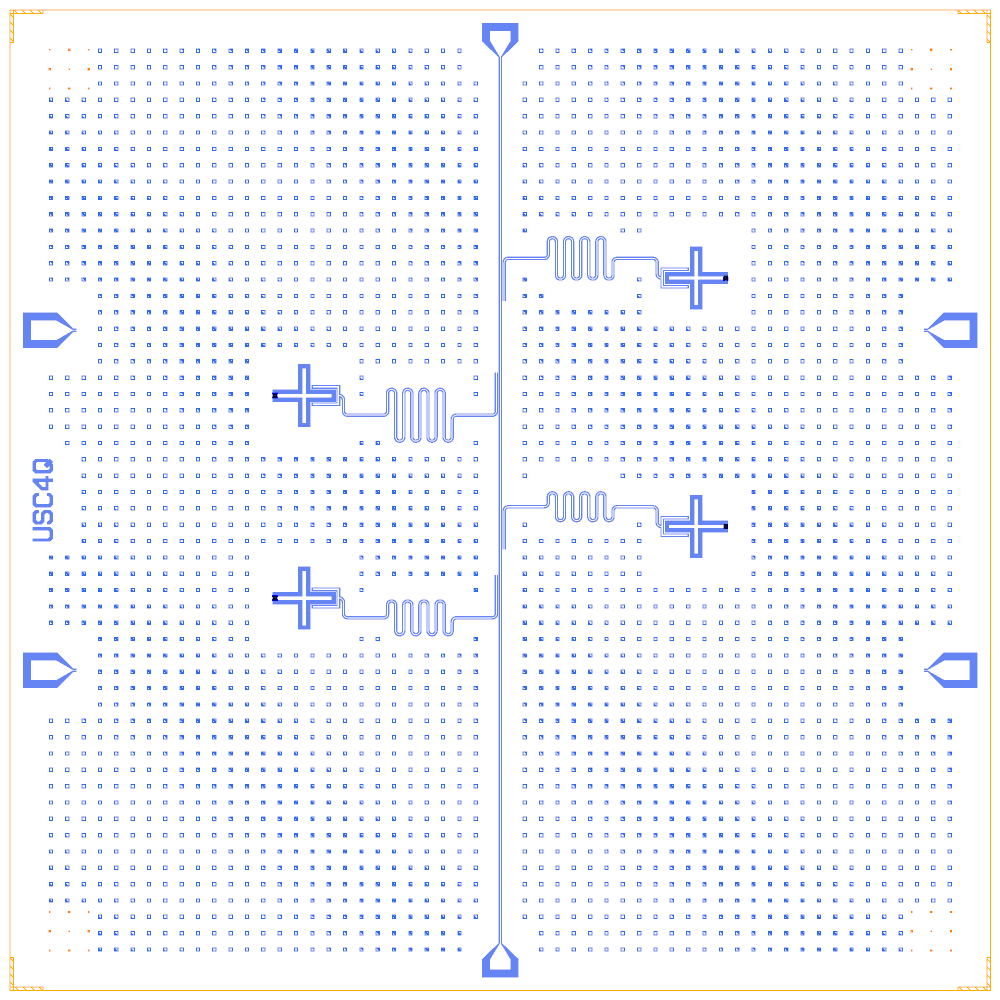

**On the chip so far:** 6 pads · 4 qubits · 0 other components · 5 routes · 0 declared couplings. **This step added** 4 route(s) `R1`, `R2`, `R3`, `R4`.

WindowsPath('build/snapshots/tutorial_5_fab_ready_chip/s5_readouts.png')

In [10]:
Y_TIE = Y0 + 2075                                # P_TOP's tie at the source position (y = 4575 µm)
with d.batch():
    for i, (name, (x, y), s, way, L, f) in enumerate(QUBITS, start=1):
        west = x < 0
        d.route(f"R{i}", f"{name}.c", fl.hanger(near=(X0, Y_TIE - s), length=325, side="right" if west else "left",
                                                ground_gap=7.9, direction=way, end="short"),
                meander=L, a=11.7, b=5.1, r=30.9).set(meanders=8)
layout_step(d, STEPS / "s5_readouts.png", size=(1000, 1000), width=400)

## Design 6 · Coupling: none

The four qubits are not coupled to each other (no bus, no coupler): each sees only its readout and its charge line.
Nothing is placed here.

## Design 7 · Routing: the four charge lines

**The charge lines** run
from each LP pad along the pad's y, turn once (r = 40 µm) and end open 284 µm from the qubit centre.

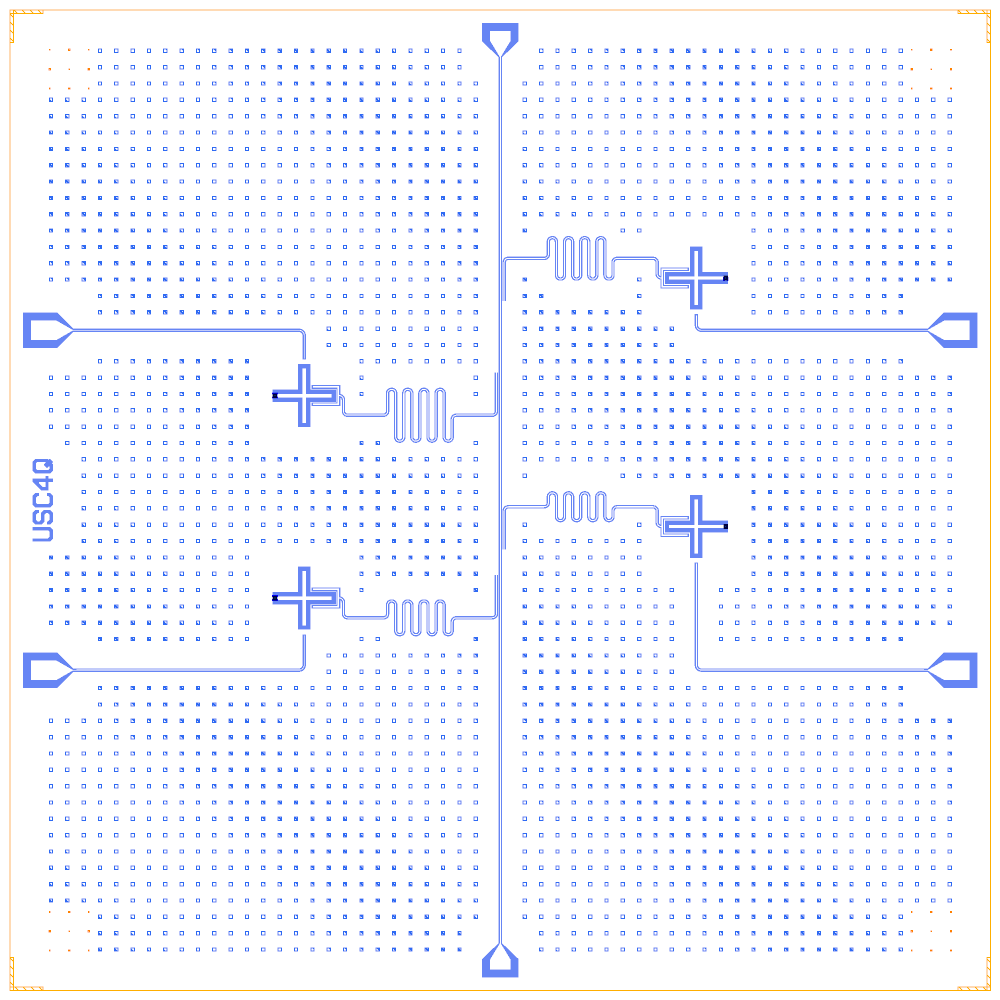

**On the chip so far:** 6 pads · 4 qubits · 0 other components · 9 routes · 0 declared couplings. **This step added** 4 route(s) `CL1`, `CL2`, `CL3`, `CL4`.

{'FL': 6730.0, 'R1': 4570.0, 'R2': 3930.0, 'R3': 3460.0, 'R4': 3100.0, 'CL1': 1943.8, 'CL2': 1843.8, 'CL3': 1993.8, 'CL4': 2543.8}


In [11]:
with d.batch():
    for i, (name, (x, y), s, way, L, f) in enumerate(QUBITS, start=1):
        py = Y0 + (1300 if y > 0 else -1300)        # the charge pad's row
        below = py < Y0 + y                         # pad row below the qubit: the line comes up from below
        tip = (X0 + x, Y0 + y + (-284 if below else 284))
        d.route(f"CL{i}", f"LP{i}.tie", Designer.free_end(tip, dir=270 if below else 90, term=6), nodes=[(X0 + x, py)],
                r=40)
layout_step(d, STEPS / "s7_charge_lines.png", size=(1000, 1000), width=400)
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})

## Design 8 · The whole chip: targets, sim groups, centring, save

**Targets, sim groups, centring, save.** The targets are the source's (f_q 3.7 GHz, α −210 MHz, f_r 5.48–8.48
GHz). One sim group per qubit with its readout, the feedline and its charge line (Q3D C-matrix and eigenmode).
`center_in_die` checks that the content sits centred in the die and shifts it if it is more than 50 µm off.

**Save.** The JSON is the deliverable. `save_design` writes it and compares it with the file it replaces (the
previous run's, the `.v1` notebook's): the segments above changed how the chip is built, not the chip, so it should say
*same design*. The file keeps the previous key order (the feedline was added before the qubits and every readout before the charge lines here), so `git diff` stays empty.

centring shift (µm): (0.0, 0.0)


**Same design as before:** `examples/designs/squadds/tutorial_5_fab_ready_chip.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer tutorial_5_fab_ready_chip: 10 instances, 9 routes, live=False> → examples\designs\squadds\tutorial_5_fab_ready_chip.json


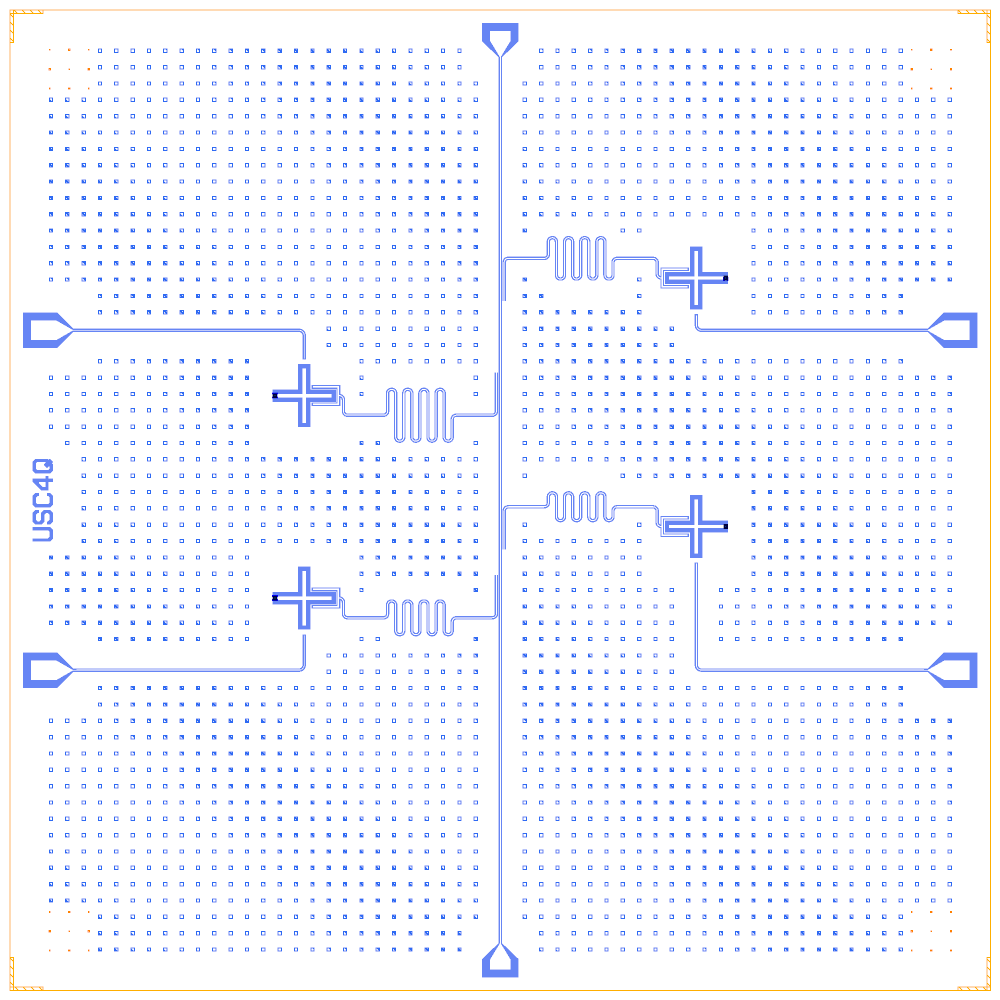

**On the chip so far:** 6 pads · 4 qubits · 0 other components · 9 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('build/snapshots/tutorial_5_fab_ready_chip/4_routes.png')

In [12]:
for i, (name, _, _, _, _, f) in enumerate(QUBITS, start=1):
    d.targets(**{name: {"f_q_GHz": 3.7, "alpha_MHz": -210}, f"R{i}": {"f_GHz": f}})
    d.sim_group(f"{name}R{i}", [name, f"R{i}", "FL", f"CL{i}"], analyses=["q3d_cmatrix", "eigenmode_epr"])
print("centring shift (µm):", center_in_die(d))
rebuild(d)
DESIGN, same = save_design(d, OUT / "tutorial_5_fab_ready_chip.json")
display(Markdown(same))
print(d, "→", DESIGN)
layout_step(d, STEPS / "4_routes.png", size=(1000, 1000), width=400)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to read. **PDK
design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): flagged,
never enforced — the rebuild keeps the source's choices. `pdk_report` adds the cheese source, the centring
and the junction types.

**From the v1 run:** 0 errors, 8 `dangling_port` warnings (each `TransmonCross`'s `squid_a` / `squid_b`: the qubit draws its own junction) and **8 PDK design warnings**: `pdk_rn` × 4 (R_n 90 kΩ from the 4.05 GHz sizing, above 40–50 kΩ) and `pdk_fq` × 4 (the source's 3.7 GHz target is below the 4–8 GHz band). They are flagged, not retuned. No `pad_edge`: the pads are at 100 µm. `pdk_report` gives the original's cheese rule drawn in the build, the content centred (0, 0) and "Quantcore Junction × 4".

In [ ]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit: each `TransmonCross` is a cross node (C to ground, the junction
to ground) and a claw node (C_g to the cross, C to ground); each readout route is a λ/4 `TLres` from the claw node,
shorted at the coupled section's far end, coupled to the feedline node by the hanger; the feedline runs between the
two 50 Ω feedline pads. The charge lines end open near the qubits: the LOM makes each a λ/2 line on its 50 Ω pad,
with no coupling to the qubit (no drive control).

In [ ]:
lb = d.lom()
show_netlist(lb)
display(Markdown("**Q1's ports → circuit nodes:**\n\n| port | node |\n|---|---|\n" + "\n".join(
    f"| `{ref}` | `{node}` |" for ref, node in sorted(lb.port_map.items()) if ref.startswith("Q1."))))

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

Each qubit with its readout and the whole feedline: QuCat's normal modes and the QuTiP-dressed f_q, α, f_r, κ, χ,
against the source's targets (the brackets: f_q 3.7 GHz, α −210 MHz, the sprayed readouts 5.48–8.48 GHz, all on
silicon in the source).

In [ ]:
targets = {**{q[0]: {"f_q_GHz": 3.7, "alpha_MHz": -210} for q in QUBITS},
           **{f"R{i}": {"f_GHz": q[5]} for i, q in enumerate(QUBITS, start=1)}}
groups = {f"{q[0]}R{i}": [q[0], f"R{i}", "FL"] for i, q in enumerate(QUBITS, start=1)}
res = simulate_groups(d, groups)
display(Markdown(groups_md(res, targets)))

**From the v1 run:** f_q 4.088 GHz for all four (the 4.05 GHz sizing plus the claw loading; target 3.7 GHz on silicon), α ≈ −213 MHz (target −210 MHz); f_r 6.12 / 6.99 / 7.82 / 8.59 GHz (targets 5.48 / 6.48 / 7.48 / 8.48 GHz: sapphire's lower εr raises every λ/4), κ 0.10–0.27 MHz, χ −0.38 … −0.20 MHz.

## LOM 2 · The LOM in two plots

The same results as pictures: (a) every normal mode of each qubit's group (QuCat; circles are qubits, squares
readouts; filled markers are the QuTiP dressed values; red bars the source's targets), (b) the dispersive shift |χ| of
each readout. From the v1 run the qubits sit 0.4 GHz above their 3.7 GHz bars (the 4.05 GHz sizing) and the readouts
above theirs (sapphire's lower εr).

In [ ]:
plot_lom(res, STEPS / "lom.png", targets=targets, title="tutorial_5_fab_ready_chip: LOM per qubit + readout")

## LOM 3 · One geometry change, by hand

Before the FEM, a design step by hand. The readout spray is set by the λ/4 lengths. Shorten R1 from 4570 to 4400 µm: its f_r rises (≈ +4 %), further
from the qubit, so |χ| drops; f_q and α barely move. The change is made on a copy (`design_copy`), so
`tutorial_5_fab_ready_chip.json` keeps the source's 4570 µm.

In [ ]:
d2 = design_copy(DESIGN)
d2["R1"].set(meander=4400)
after = simulate_groups(d2, {"Q1R1": groups["Q1R1"]})
display(Markdown("**R1: 4570 → 4400 µm**\n\n" + params_delta_md({"Q1R1": res["Q1R1"]}, after)))

**From the v1 run:** R1's f_r moves from 6.119 to 6.329 GHz (+210 MHz), |χ| drops from 0.381 to 0.346 MHz and κ rises from 0.101 to 0.111 MHz; f_q and α do not move (< 0.1 MHz).

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/squadds/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

One job per sim group and analysis: the group is cut out of the chip with its margin, every line leaving the
box ends in a port, junctions are lumped ports, and the ground grid is removed (simulation exports never have
cheese). The table lists each job's ports and C-matrix nets (named after islands, couplers and routes, so the
result maps back onto the LOM nodes).

`RUN_FEM = False` only exports, and the next cells load results kept from an earlier solve. `FEM_FAST` (a switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line
equivalent is `qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

The jobs: one Q3D C-matrix and one eigenmode job per qubit with its readout, the feedline and its charge line.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/squadds/fem/: solved results are kept here
jobs = export_sims(DESIGN, analysis="q3d_cmatrix")          # every sim group: one C-matrix job each
jobs_eig = export_sims(DESIGN, analysis="eigenmode_epr")    # and one eigenmode / EPR job each
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrix

The capacitance of each qubit's group: the cross, its claw, the readout, the feedline and the charge line the box
cuts, as named nets. Each net is named after its LOM node, so the matrix goes straight into the circuit (Results 3) —
including the charge line's capacitance to the cross, which the LOM leaves out (Check 2: no drive control).
`fem_stage` solves each job with `RUN_FEM`, else loads its kept results, else says that there are none (four jobs,
one after the other).

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The same four boxes in HFSS eigenmode: the junction is a lumped L_J ‖ C_J sheet, the lines the box cuts end in 50 Ω,
so each mode's Q gives κ (and the charge line's share of it, a Purcell loss the LOM does not have). pyEPR (run inside
qcc's own AEDT, never KQC's `run_pyepr_t1_estimate.py`) turns the junction's energy participation p_J into dressed
frequencies, α and χ.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives the S-parameters of the same box. The library cannot hand the solved eigenmode
**mesh** itself to a driven setup (no such option yet), so `driven_from_eigenmode` does the nearest honest thing: the
same sim group and box, the eigenmode job's mesh seeds (the gap and junction-island seeds that resolved the modes),
the adaptive-mesh frequency at the eigenmode's readout mode (the LOM's f_r before the eigenmode is solved) and a fast
sweep around it (0.4 GHz below to 0.2 GHz above). Here for `Q1R1`: its readout is a hanger on the feedline, so S21 between the two
feedline ends the box cuts shows the notch (f_r and the external κ).

In [ ]:
f_r0 = res["Q1R1"].params.get("R1.f_GHz")                # the LOM's readout frequency (LOM 1)
jobs_drv = driven_from_eigenmode(DESIGN, "Q1R1", jobs_eig["Q1R1"][0], keep_eig["Q1R1"], f_guess=f_r0)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["Q1R1"]:
    display(Markdown(driven_md(keep_drv["Q1R1"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: the qubit; ≈ 0: the readout), with the LOM's frequencies of the
same components as dashed lines. The tables below list the modes and the pyEPR values.

In [ ]:
PAIRS = {g: (sel[0], sel[1], g) for g, sel in groups.items()}   # sim group → (qubit, readout, LOM 1 group)
lom_f = {}
for g, (qb, rr, lg) in PAIRS.items():
    p = res[lg].params
    lom_f[qb], lom_f[rr] = p.get(f"{qb}.f_q_GHz"), p.get(f"{rr}.f_GHz")
plot_eigenmodes(keep_eig, STEPS / "eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode jobs in the LOM's terms: each qubit's mode is the one its own junction participates in most, the
readout's the remaining mode nearest the LOM's f_r; f_q and f_r are pyEPR's dressed frequencies, α and χ its Kerr
terms, κ = f/Q of the 50 Ω-terminated box (bulk-dielectric loss removed). The driven run adds its S21 notch where it
finds one.

In [ ]:
fem_values = {}
for g, (qb, rr, lg) in PAIRS.items():
    if keep_eig.get(g):
        fem_values[g] = epr_values(keep_eig[g], {qb: rr}, {rr: lom_f[rr]})
if keep_drv["Q1R1"]:
    qb, rr, _ = PAIRS["Q1R1"]
    fem_values.setdefault("Q1R1", {}).update(
        {f"driven {k}": v for k, v in driven_values(keep_drv["Q1R1"], rr, lom_f[rr]).items()})
if fem_values:
    display(Markdown("| group | quantity | FEM |\n|---|---|---|\n" + "\n".join(
        f"| {g} | `{k}` | {v:.5g} |" for g, vals in fem_values.items() for k, v in vals.items() if k != "modes")))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list f_q and α of each qubit and f_r, χ, κ of "
          "its readout from pyEPR, and the S21 notch of R1.")

## Results 3 · FEM against the LOM

Two comparisons per qubit. **LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates of the simulated
components by the C-matrix values (matched by net name; the other branches keep their estimates) and the same LOM
runs again. **FEM directly:** the eigenmode (pyEPR) values of Results 2. The left column is the LOM on the component
estimates (LOM 1).

In [ ]:
from quantcore_circuits.circuit.fill import fill
from quantcore_circuits.lom.simulate import simulate

rows = []
for g, (qb, rr, lg) in PAIRS.items():
    lom_p = res[lg].params
    keys = [f"{qb}.f_q_GHz", f"{qb}.alpha_MHz", f"{rr}.f_GHz", f"{rr}.chi_MHz", f"{rr}.kappa_MHz"]
    if keep_q3d.get(g):
        on_fem = simulate(fill(d.lom(select=groups[lg]).model, DESIGN, keep_q3d[g]), max_modes=2).params
        rows += [(k, lom_p.get(k), on_fem.get(k), f"{g}: LOM on the Q3D C-matrix") for k in keys]
    rows += [(k, lom_p.get(k), fem_values[g][k], f"{g}: eigenmode + pyEPR") for k in keys if k in fem_values.get(g, {})]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts f_q, α, f_r, χ and κ of the LOM next to the LOM "
          "on the Q3D C-matrix and next to the eigenmode, with the difference in %.")

## Results 4 · Feedback: one step towards the targets

The design carries the source's targets (Design 8): f_q 3.7 GHz and α −210 MHz per qubit, the readout spray 5.48 /
6.48 / 7.48 / 8.48 GHz. The qubits' 3.7 GHz is below the PDK band, and the junctions were sized for the band's floor,
4.05 GHz, instead (Design 4), so the feedback copy asks **4.05 GHz** of every qubit (α −210 MHz kept) and keeps the
readouts' targets (`target_copy` → `build/tutorial_5_fab_ready_chip_target.json`; the design file keeps the source's
targets). From the v1 run the qubits sit 38 MHz above that (4.088 GHz), α on target (−213 MHz), and the readouts
1–12 % high (6.12 / 6.99 / 7.82 / 8.59 GHz: sapphire's lower εr), so the feedback lengthens the readouts — R1 by about
12 % — and raises L_J a little. A longer meander takes more room: read the revision's DRC line.

`loop.analyse` runs the estimators (QuCat, SQcircuit, scqubits, Metal LOM) on every qubit–readout pair of the
circuit — four here, so it takes minutes — on the Q3D values where a solve was kept, and picks one value per quantity
(the consensus). `loop.feedback` anchors a surrogate on that point and proposes the knobs that put the targets inside
their tolerances (f_q ± 20 MHz, α ± 10 MHz, f_r ± 10 MHz); the proposal is written as revision 1, built and
netlist-checked. **No PDK L_J bounds:** the 4.05 GHz junction is at R_n ≈ 92 kΩ (`pdk_rn`, flagged, not retuned), so
`pdk_lj_bounds` would pull it into the 40–50 kΩ window, i.e. the qubits to ≈ 5.7 GHz inside the readout spray. The
revision changes the LOM's L_J; to draw it, size the fingers with `trilayer_junction("metal:TransmonCross", lj_nH=...)`,
as Design 4 does.

In [ ]:
from quantcore_circuits import loop
from quantcore_circuits.assembly.drc import check

TARGETS = {q[0]: {"f_q_GHz": 4.05, "alpha_MHz": -210} for q in QUBITS}   # the sizing frequency, in the PDK band
DESIGN_T = target_copy(DESIGN, TARGETS)          # the readouts keep the source's spray
BOUNDS = None                                    # not pdk_lj_bounds(DESIGN): the junctions are outside the window
FILL = [k for k in keep_q3d.values() if k] or None   # kept Q3D results fill the circuit; None: the LOM estimates
an0 = loop.analyse(str(DESIGN_T), FILL, readout=False)
display(Markdown(consensus_md(an0, only_targets=True)))
prop, rev1, rev1_build = loop.feedback(an0, design_source=str(DESIGN_T), bounds=BOUNDS)
display(Markdown(proposal_md(prop)))
now = {r.param: r.chosen for r in an0.rows}
display(Markdown(before_after_md({k: now.get(k) for k in prop.residuals}, {k: prop.predicted[k] for k in prop.residuals})))
print("revision 1:", rev1, "· DRC:", "clean" if check(rev1_build).ok else "ERRORS")

## Results 5 · Iterate to the target

The feedback cell, repeated: analyse the revision → on target? → else feed back again → the next revision, until
every target is inside its tolerance or `MAX_ITER` revisions are made (`build/tutorial_5_fab_ready_chip/revisions/`). Without `RUN_FEM`
each revision is judged on the LOM. With `RUN_FEM = True` the Q3D jobs of the four qubit groups are exported and solved first for each revision
(`solve_rev`), so the loop closes on FEM values (each solve takes AEDT minutes). The table shows each iteration's
values against the targets and the knobs it moved; the plot the residual in tolerances (on target below 1).

In [ ]:
def solve_rev(rev, k):
    """RUN_FEM: revision k's four Q3D jobs, exported to build/jobs/rev<k>/ and solved (kept in fem/rev<k>/)."""
    jobs_k = {g: export_sims(rev, [g], root=f"build/jobs/rev{k}")[g] for g in list(groups)}
    kept = fem_stage(jobs_k, RUN_FEM, KEEP / f"rev{k}", force=RESOLVE, aedt=AEDT_MODE)
    return [v for v in kept.values() if v] or None


history, last, an_last = iterate_to_target(DESIGN_T, FILL, max_iter=MAX_ITER, bounds=BOUNDS,
                                           solve=solve_rev if RUN_FEM else None, an=an0)
display(Markdown(history_md(history)))
plot_iterations(history, STEPS / "iterate.png")
print("last design:", last, "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

**The design file.** `tutorial_5_fab_ready_chip.json` (saved in Design 8) is the whole design: `qcc build
examples/designs/squadds/tutorial_5_fab_ready_chip.json` rebuilds `build/tutorial_5_fab_ready_chip.oas` + its sidecar, and the KLayout plugin,
`qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the filled 3/0 keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese
hole), the trilayer fingers 2/0 + 4/0 and spacer 50–53/0,
and the frame (100/0, 1000/0, 1001/0). The cheese source is `build`: the source's own rule drawn in the build (25 µm holes on a 125 µm pitch,
100 µm from 3/0, 200 µm from the die edge), and no PDK band is added. In the v1 run: 1/0 2542 polygons, 3/0 2534 (the keep-outs plus the holes), 2524 holes. Corner rounding (fab only) is skipped unless `FULL_FAB`;
`qcc mask examples/designs/squadds/tutorial_5_fab_ready_chip.json` writes the complete file.

In [ ]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

**Simulation export options.** A simulation export never has cheese; airbridges are dropped for speed unless
`airbridges=True` (or the sim group's `settings={"airbridges": True}`), and the builder notes which crossing
lines are then open. `setup.geometry` says what the export left out. This chip has no airbridges, so both settings give the same geometry.

In [ ]:
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "Q1R1", "q3d_cmatrix", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

## Fab 2 · Snapshots

The full chip (the six pads at the die edges, the source's cheese over the free ground, the frame); qubit Q1 with
its claw and charge-line end; its junction; the R1 coupled section on the feedline; the die frame's south-west
corner (dicing L on 1000/0, 3 × 3 alignment grid on 1001/0); and Q1 in the **fab view** (the mask from Fab 1: 1/0
with the cheese holes, 3/0, the trilayer junction layers). The chip boundary 100/0 is drawn as an outline. The
source's GDS is not in this checkout, so it is not shown; compare the tutorial's own picture.

In [ ]:
show_snapshot(d, OUT / "tutorial_5_fab_ready_chip.png", size=(1600, 1600))
qx, qy = X0 - 1500, Y0 + 800
show_snapshot(d, OUT / "tutorial_5_fab_ready_chip_q1.png", box=(qx - 350, qy - 350, qx + 450, qy + 350), size=(1200, 1050), width=450)
show_snapshot(d, OUT / "tutorial_5_fab_ready_chip_jj.png", box=(qx - 280, qy - 40, qx - 200, qy + 40), width=300)
show_snapshot(d, OUT / "tutorial_5_fab_ready_chip_coupler.png", box=(X0 - 120, Y0 + 600, X0 + 60, Y0 + 1020), size=(600, 1400), width=220)
show_snapshot(d, OUT / "tutorial_5_fab_ready_chip_frame.png", box=(-1250, -1250, -350, -350), size=(900, 900), width=300)
snap_file(Path("build") / "tutorial_5_fab_ready_chip_fab.oas", OUT / "tutorial_5_fab_ready_chip_fab_q1.png",
          box=(qx - 450, qy - 450, qx + 450, qy + 450), size=(1200, 1200), width=420);

## Summary

| | |
|---|---|
| **matches the source** | the four `TransmonCross` qubits with the source's options and positions; the readout lengths 4570 / 3930 / 3460 / 3100 µm with the 325 µm coupled sections at the source's centres; the feedline and charge-line paths; the targets; the source's cheese rule |
| **differs (PDK)** | the 7.5 mm Quantcore die with its frame; the six pads 100 µm from the die edge (longer feedline and charge lines); sapphire instead of silicon; Quantcore trilayer junctions sized for 4.05 GHz instead of the database's Dolan junction |
| **assumed** | the claw gap and ground spacing; the resonator gap 5.1 µm |
| **PDK design warnings** | `pdk_rn` × 4 (R_n 90 kΩ) and `pdk_fq` × 4 (target 3.7 GHz): flagged, not retuned |
| **layout** | built in segments (die, pads, the feedline, the qubits, the readouts, the charge lines, the whole chip); the saved JSON is the v1 notebook's |
| **feedback** | on a copy, the qubits at their 4.05 GHz sizing frequency (α −210 MHz) and the source's readout spray: `loop.analyse` → `loop.feedback` → revisions until on target (LOM; FEM with `RUN_FEM`); no PDK L_J bounds |
| **FEM** | 8 jobs exported (`build/jobs/tutorial_5_fab_ready_chip_*`: Q3D + eigenmode per qubit) and a driven run for Q1R1, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the Simulate and Results cells |